# imports

In [1]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 10.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from torch.utils.data import TensorDataset, DataLoader, random_split
from tqdm import tqdm
from torchmetrics import Accuracy

In [3]:
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# load data

In [11]:
BASE_DIR = "/content/drive/MyDrive/howsam_DL/week6/har_dataset/UCI HAR Dataset"

In [12]:
for root, dir, file in os.walk(BASE_DIR):
    print("root:", root)
    print("dir:", dir)
    print("files:", file)

root: /content/drive/MyDrive/howsam_DL/week6/har_dataset/UCI HAR Dataset
dir: ['train', 'test']
files: ['activity_labels.txt', 'features.txt', 'features_info.txt', 'README.txt', '.DS_Store']
root: /content/drive/MyDrive/howsam_DL/week6/har_dataset/UCI HAR Dataset/train
dir: ['Inertial Signals']
files: ['y_train.txt', 'subject_train.txt', 'X_train.txt']
root: /content/drive/MyDrive/howsam_DL/week6/har_dataset/UCI HAR Dataset/train/Inertial Signals
dir: []
files: ['body_acc_x_train.txt', 'body_acc_y_train.txt', 'body_acc_z_train.txt', 'total_acc_x_train.txt', 'total_acc_y_train.txt', 'total_acc_z_train.txt', 'body_gyro_x_train.txt', 'body_gyro_y_train.txt', 'body_gyro_z_train.txt']
root: /content/drive/MyDrive/howsam_DL/week6/har_dataset/UCI HAR Dataset/test
dir: ['Inertial Signals']
files: ['y_test.txt', 'subject_test.txt', 'X_test.txt']
root: /content/drive/MyDrive/howsam_DL/week6/har_dataset/UCI HAR Dataset/test/Inertial Signals
dir: []
files: ['body_acc_y_test.txt', 'body_acc_x_test.

In [13]:
SIGNALS_NAME = ['body_acc_x', 'body_acc_y', 'body_acc_z', 'total_acc_x'
                , 'total_acc_y', 'total_acc_z', 'body_gyro_x', 'body_gyro_y'
                , 'body_gyro_z']

In [14]:
def load_har_data(splitter, base_dir=BASE_DIR):
  signals = []
  for signal in SIGNALS_NAME:
    filename = f"{base_dir}/{splitter}/Inertial Signals/{signal}_{splitter}.txt"
    file = np.loadtxt(filename)
    signals.append(file)

  y_path = f"{base_dir}/{splitter}/y_{splitter}.txt"
  y_file = np.loadtxt(y_path)

  # ([9, 7352, 128])  ==> ([7352, 128, 9])
  data_signals = torch.FloatTensor(signals).permute(1, 2, 0)

  # labels must start from 0 to 5 (it is 1 to 7)
  # y ==> ([0, 1, 2, 3, 4, 5])
  labels = torch.LongTensor(y_file) - 1

  return data_signals, labels

In [15]:
X_train, y_train = load_har_data("train")
X_test, y_test = load_har_data("test")

/tmp/ipykernel_627/3967924238.py:12: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  data_signals = torch.FloatTensor(signals).permute(1, 2, 0)


### plot

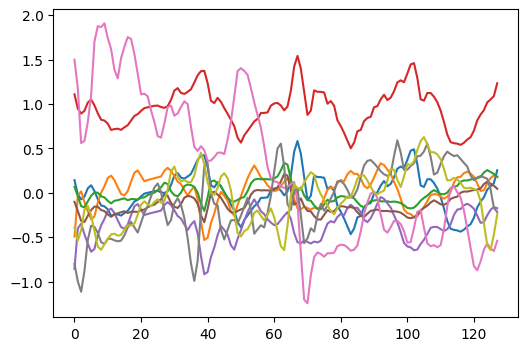

In [16]:
plt.figure(figsize=(6, 4))
plt.plot(X_train[500])
plt.show()

# create validation set from subjects

In [17]:
train_subjects = np.loadtxt(f"{BASE_DIR}/train/subject_train.txt"
                            , dtype=int)

gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)

train_idx, valid_idx = next(gss.split(X_train, y_train, groups=train_subjects))

X_train_final = X_train[train_idx]
y_train_final = y_train[train_idx]

X_valid = X_train[valid_idx]
y_valid = y_train[valid_idx]

In [18]:
print(f"x_train shape: {X_train_final.shape}")
print(f"y_train shape: {y_train_final.shape}")
print(f"x_valid shape: {X_valid.shape}")
print(f"y_valid shape: {y_valid.shape}")
print(f"x_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

x_train shape: torch.Size([6220, 128, 9])
y_train shape: torch.Size([6220])
x_valid shape: torch.Size([1132, 128, 9])
y_valid shape: torch.Size([1132])
x_test shape: torch.Size([2947, 128, 9])
y_test shape: torch.Size([2947])


# prepare for feeding model

In [19]:
# tensor dataset
train_set = TensorDataset(X_train_final, y_train_final)
valid_set = TensorDataset(X_valid, y_valid)
test_set = TensorDataset(X_test, y_test)

# to data loader
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=128, shuffle=False)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False)

# utils

In [20]:
class AverageMeter(object):
  def __init__(self):
    self.reset()

  def reset(self):
    self.val = 0
    self.count = 0
    self.sum = 0
    self.avg = 0

  def update(self, val, n=1):
    self.val = val
    self.sum += val * n
    self.count += n
    self.avg = self.sum / self.count

# functions

In [21]:
def train_one_epoch(model, train_loader, loss_fn, optimizer, epoch=None):

  model.train()
  train_loss = AverageMeter()
  train_acc = Accuracy(task="multiclass", num_classes=6).to(device)

  with tqdm(train_loader, unit='batch') as tepoch:
    for inputs, targets in tepoch:
      if epoch is not None:
        tepoch.set_description(f"Epoch {epoch}")

      inputs = inputs.to(device)
      targets = targets.to(device)
      outputs = model(inputs)

      loss = loss_fn(outputs, targets)

      loss.backward()
      optimizer.step()
      optimizer.zero_grad()

      train_loss.update(loss.item())
      train_acc(outputs, targets.int())

      tepoch.set_postfix(loss=train_loss.avg,
                         acc=100. * train_acc.compute().item())

  return model, train_loss.avg, train_acc.compute().item()

In [22]:
def validation(model, valid_loader, loss_fn):

  model.eval()

  valid_loss = AverageMeter()
  valid_acc = Accuracy(task='multiclass', num_classes=6).to(device)

  with torch.no_grad():
    for inputs, targets in valid_loader:
      inputs = inputs.to(device)
      targets = targets.to(device)

      outputs = model(inputs)

      loss = loss_fn(outputs, targets)

      valid_loss.update(loss.item())
      valid_acc(outputs, targets.int())

  return valid_loss.avg, valid_acc.compute().item()

# costum model

In [23]:
class RNNModel(nn.Module):
  def __init__(self, RNN, input_size, hidden_size, num_layers, n_class):
    super().__init__()
    self.rnn = RNN(input_size, hidden_size, num_layers, batch_first=True)
    self.fc = nn.Linear(hidden_size, n_class)

  def forward(self, x):
    output, hn = self.rnn(x)
    y = self.fc(output[:, -1, :])    # many to one
    return y

In [24]:
class RNNModel(nn.Module):
  def __init__(self, RNN, input_size, hidden_size, num_layers, n_class):
    super().__init__()
    self.rnn = RNN(input_size, hidden_size, num_layers, batch_first=True)
    self.fc = nn.Linear(hidden_size, n_class)

  def forward(self, x):
    output, hn = self.rnn(x)
    y = self.fc(output)    # many to one
    y = y.mean(dim=1)
    return y

# device

In [33]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device is", device)

n_params = [torch.numel(p) for p in rnn_model.parameters()]
print("number of parameters", n_params)

device is cuda
number of parameters [4608, 65536, 512, 512, 65536, 65536, 512, 512, 768, 6]


# loss function & optimizer

In [32]:
rnn_model = RNNModel(nn.LSTM, 9, 128, 2, 6).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(rnn_model.parameters(), lr=0.05, momentum=0.9)

# efficient value for lr

## one batch and use loss fn

In [34]:
xbatch, ybatch = next(iter(train_loader))
xbatch = xbatch.to(device)
ybatch = ybatch.to(device)

output = rnn_model(xbatch)
loss = loss_fn(output, ybatch)
print(loss)

tensor(1.7838, device='cuda:0', grad_fn=<NllLossBackward0>)


## random split for mini loader many epochs

In [35]:
mini_batch, _ = random_split(train_set, [500, len(train_set) - 500])
mini_loader = DataLoader(mini_batch, batch_size=100)

num_epochs = 100

In [36]:
for epoch in range(num_epochs):
  train_one_epoch(rnn_model, mini_loader, loss_fn, optimizer, epoch)

Epoch 99: 100%|██████████| 5/5 [00:00<00:00, 74.35batch/s, acc=78.4, loss=0.516]


## best LR

In [39]:
num_epochs = 5


for lr in [0.01, 0.05, 0.1, 0.5]:
  rnn_model = RNNModel(nn.LSTM, 9, 128, 2, 6).to(device)
  optimizer = optim.SGD(rnn_model.parameters(), lr=lr, momentum=0.9)

  print("LR", lr)

  for epoch in range(num_epochs):
    rnn_model, _, _ = train_one_epoch(rnn_model, train_loader, loss_fn, optimizer, epoch)
  print()

LR 0.01


Epoch 4: 100%|██████████| 98/98 [00:01<00:00, 93.89batch/s, acc=46.8, loss=1.17]



LR 0.05


Epoch 4: 100%|██████████| 98/98 [00:01<00:00, 97.42batch/s, acc=76.4, loss=0.626]



LR 0.1


Epoch 4: 100%|██████████| 98/98 [00:01<00:00, 92.14batch/s, acc=89.2, loss=0.263]



LR 0.5


Epoch 4: 100%|██████████| 98/98 [00:01<00:00, 96.58batch/s, acc=92.8, loss=0.162]

# train with whole set

In [43]:
rnn_model = RNNModel(nn.LSTM, 9, 128, 2, 6).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(rnn_model.parameters(), lr=0.5, momentum=0.9)

best_valid_loss = torch.inf
counter = 0

In [44]:
train_loss_hist = []
train_acc_hist = []

valid_loss_hist = []
valid_acc_hist = []

In [45]:
num_epochs = 50

for epoch in range(num_epochs):
  _, train_loss, train_acc = train_one_epoch(rnn_model, train_loader, loss_fn, optimizer, epoch)

  valid_loss, valid_acc = validation(rnn_model, valid_loader, loss_fn)

  print(f"validation loss is: {valid_loss:.3}")

  train_loss_hist.append(train_loss)
  train_acc_hist.append(train_acc)

  valid_loss_hist.append(valid_loss)
  valid_acc_hist.append(valid_acc)

  if valid_loss < best_valid_loss:
    best_valid_loss = valid_loss
    torch.save(rnn_model.state_dict(), '/content/drive/MyDrive/Adult-Income-Binary-Classification/models/best_rnn_model.pt')
    print("model saved !")
  print()
  counter += 1

Epoch 0: 100%|██████████| 98/98 [00:01<00:00, 84.88batch/s, acc=47, loss=1.24]


validation loss is: 0.939
model saved !



Epoch 1: 100%|██████████| 98/98 [00:01<00:00, 95.77batch/s, acc=77.2, loss=0.543]


validation loss is: 0.811
model saved !



Epoch 2: 100%|██████████| 98/98 [00:01<00:00, 96.19batch/s, acc=86.9, loss=0.332]


validation loss is: 0.757
model saved !



... (90 outputs left out)

Epoch 48: 100%|██████████| 98/98 [00:01<00:00, 87.70batch/s, acc=95.1, loss=0.108]


validation loss is: 0.324



Epoch 49: 100%|██████████| 98/98 [00:01<00:00, 90.86batch/s, acc=95, loss=0.106]


validation loss is: 0.199



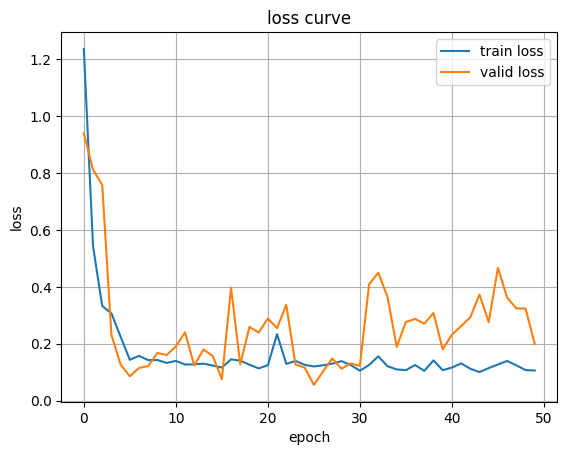

In [46]:
plt.plot(range(counter), train_loss_hist, label="train loss")
plt.plot(range(counter), valid_loss_hist, label="valid loss")
plt.title("loss curve")
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.grid(True)
plt.show()

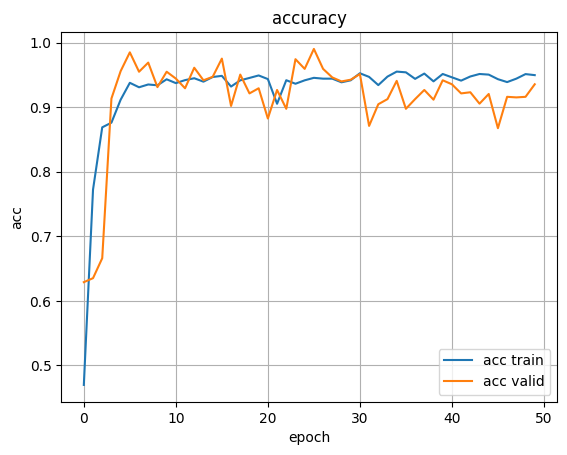

In [48]:
plt.plot(range(counter), train_acc_hist, label="acc train")
plt.plot(range(counter), valid_acc_hist, label="acc valid")
plt.title("accuracy")
plt.xlabel('epoch')
plt.ylabel('acc')
plt.legend()
plt.grid(True)
plt.show()

# test best model

## load model

In [49]:
rnn_model.load_state_dict(
    torch.load('/content/drive/MyDrive/Adult-Income-Binary-Classification/models/best_rnn_model.pt', map_location=device)
)

rnn_model.eval()

RNNModel(
  (rnn): LSTM(9, 128, num_layers=2, batch_first=True)
  (fc): Linear(in_features=128, out_features=6, bias=True)
)

In [66]:
def test_model(model, test_loader, loss_fn, device):

  model.eval()

  test_loss = AverageMeter()
  test_acc = AverageMeter()

  y_true = []
  y_pred = []

  with torch.no_grad():
    for inputs, targets in test_loader:
      inputs = inputs.to(device)
      targets = targets.to(device)

      # forward
      outputs = model(inputs)

      # Loss
      loss = loss_fn(outputs, targets)
      # because nn.CEL output for 6 features is for example (0.1, 0.5, 0.6, ...) mean of them
      # so we multiply this mean number to batch size to accumulate the total loss across all samples.
      test_loss.update(loss.item(), inputs.size(0))   # loss * 64 (batch)

      # predict
      predictions = torch.argmax(outputs, dim=1)

      # accuracy
      correct = (predictions == targets).sum().item()
      accuracy = correct / targets.size(0)

      test_acc.update(accuracy, inputs.size(0))

      # Store predictions and actual labels
      y_true.extend(targets.cpu().numpy())
      y_pred.extend(predictions.cpu().numpy())

  print(f"Test Loss: {test_loss.avg:.4f}")
  print(f"Test Accuracy: {test_acc.avg:.4f}")

  return test_loss.avg, test_acc.avg, y_true, y_pred

In [67]:
test_loss, test_acc, y_true, y_pred = test_model(rnn_model, test_loader, loss_fn, device)
test_loss, test_acc

Test Loss: 0.4277
Test Accuracy: 0.9114


(0.42766558585993697, 0.9114353579911775)